**Part of student 1.** This notebook holds only the cells of student 1 and the shared ones (title and conclusions); the other cells are in `sts-student2.ipynb`. The final notebook `sts-project.ipynb` is built from the two parts with `python sts_parts.py merge --run`.

- Edit only this notebook, not the final one. New cells are placed after the cell above them.
- The cells of the two parts are interleaved, so this notebook does not run from top to bottom by itself. To work on one cell, run the cell below with the position of that cell (`python sts_parts.py list` shows the positions): it runs everything that comes before it, from both parts.


In [ ]:
# Helper, not part of the final notebook: run the code cells of both parts that come before a position.
from sts_parts import run_before
# run_before(30)   # e.g. before working on the cell at position 30


# IHLT Project: Semantic Textual Similarity

**Students:** _\_\_\_\_\__ and _\_\_\_\_\__

This notebook builds a system for the **Semantic Textual Similarity (STS)** task of SemEval 2012 (Task 6): given two sentences, predict how similar their meaning is, from 0 (different topics) to 5 (completely equivalent).

The system computes similarity measures between the two sentences of each pair and combines them. Following the statement of the project, we explore:

1. **Lexical dimension**: overlap of words, lemmas, n-grams and characters, WordNet similarities between words, numbers and length.
2. **Syntactic dimension alone**: similarity of the POS tag sequences, of the chunk structure and of the dependency trees, without looking at the words.
3. **Combination** of both: the lexical and syntactic features, plus lexico-syntactic features (words compared within the same category, chunk or dependency relation).

And, following the strategies proposed in the statement, we compare several ways of turning the measures into a score: **one measure alone**, a **plain average** of measures, **learned weights** (a linear model) and a **non-linear model** that predicts the score from all the measures.

**Constraints.** Only the data of the task is used (train set for training, test set only for the final evaluation). **No pre-trained word or sentence embeddings are used.** The linguistic processing is done with **NLTK** (tokenizer, POS tagger, WordNet lemmatizer, stopwords, chunker, WordNet and its information content) and with the dependency parser of **spaCy** (`en_core_web_sm`, a model without word vectors, as in Lab 8). The effect of the spaCy features is measured separately in section 7.4.

**Evaluation.** Pearson correlation with the gold standard, using the three official measures of the task: **ALL** (Pearson on the concatenation of the five test sets), **ALLnrm** (the same after a least-squares normalization of each test set) and **Mean** (mean of the Pearson of each test set, weighted by its number of pairs).

**Contents**

1. Setup and data
2. Evaluation and official results
3. Preprocessing
4. Features: lexical, syntactic and lexico-syntactic
5. From single measures to learned models (train set only)
6. Results on the test set and comparison with the official results
7. Analysis
8. Comparison with the systems of the participants
9. Conclusions

## 1. Setup and data

In [1]:
from pathlib import Path

# The notebook runs from project/, so the workspace root is the parent folder.
ROOT = Path.cwd().parent

NLTK_DIR = ROOT / "models" / "nltk_data"
DATA_DIR = ROOT / "data"
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test_gold"
SUBMISSIONS_DIR = DATA_DIR / "task6-submissions"

# Notebook libs
import math
import re
import tarfile
import time
import urllib.request
import warnings
from collections import Counter
from functools import lru_cache

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import spacy
from nltk.corpus import stopwords, wordnet as wn, wordnet_ic
from scipy.stats import pearsonr
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

# NLTK packages needed by this notebook
nltk.data.path.insert(0, str(NLTK_DIR))
for package in ["punkt_tab", "averaged_perceptron_tagger_eng", "wordnet", "omw-1.4", "stopwords", "wordnet_ic"]:
    nltk.download(package, download_dir=NLTK_DIR, quiet=True)

# Data of the task (train, test with gold standard, and the submissions of the participants).
# Downloaded from the course page into data/ if they are not there yet.
URL = "https://smedina-upc.github.io/ihlt/sts/resources/"
for folder, archive, extracted in [(TRAIN_DIR, "train.tgz", "train"),
                                   (TEST_DIR, "test-gold.tgz", "test-gold"),
                                   (SUBMISSIONS_DIR, "task6-submissions.tgz", "task6-submissions")]:
    if not folder.exists():
        DATA_DIR.mkdir(exist_ok=True)
        path, _ = urllib.request.urlretrieve(URL + archive, DATA_DIR / archive)
        with tarfile.open(path) as tar:
            tar.extractall(DATA_DIR, filter="data")
        (DATA_DIR / extracted).rename(folder)
print("Data folders:", [f.name for f in [TRAIN_DIR, TEST_DIR, SUBMISSIONS_DIR]])

Data folders: ['train', 'test_gold', 'task6-submissions']


In [2]:
# The five test sets and the three training sets (the surprise sets have no training data).
TRAIN_SETS = ["MSRpar", "MSRvid", "SMTeuroparl"]
TEST_SETS = ["MSRpar", "MSRvid", "SMTeuroparl", "surprise.OnWN", "surprise.SMTnews"]

def load(folder, name):
    """Sentence pairs and gold scores of one dataset.
    The files are read line by line (and not with pandas) because some sentences contain quotes."""
    with open(folder / f"STS.input.{name}.txt", encoding="utf-8") as f:
        pairs = [line.rstrip("\n").split("\t") for line in f]
    with open(folder / f"STS.gs.{name}.txt") as f:
        gold = np.array([float(line) for line in f if line.strip()])
    assert len(pairs) == len(gold) and all(len(p) == 2 for p in pairs)
    return pairs, gold

data = {("train", s): load(TRAIN_DIR, s) for s in TRAIN_SETS}
data.update({("test", s): load(TEST_DIR, s) for s in TEST_SETS})

overview = pd.DataFrame([{"split": split, "dataset": name, "pairs": len(gold),
                          "mean gold": gold.mean(), "std gold": gold.std(),
                          "% gold >= 4": (gold >= 4).mean() * 100}
                         for (split, name), (pairs, gold) in data.items()])
overview.round(2)

,split,dataset,pairs,mean gold,std gold,% gold >= 4
0,train,MSRpar,750,3.32,0.93,27.07
1,train,MSRvid,750,2.14,1.59,17.07
2,train,SMTeuroparl,734,4.31,0.71,82.15
3,test,MSRpar,750,3.27,0.92,22.53
4,test,MSRvid,750,2.30,1.64,20.00
5,test,SMTeuroparl,459,4.55,0.52,90.63
6,test,surprise.OnWN,750,3.87,1.02,59.33
7,test,surprise.SMTnews,399,4.33,0.82,79.70


In [3]:
# One example of each dataset, to see how different they are.
for name in TEST_SETS:
    pairs, gold = data[("test", name)]
    i = int(np.argmin(np.abs(gold - 3)))  # a pair with an intermediate score
    print(f"{name} (gold {gold[i]})\n  S1: {pairs[i][0]}\n  S2: {pairs[i][1]}\n")

MSRpar (gold 3.0)
  S1: Coupling, an American version of a hit British comedy, will get the valuable Thursday 9:30 p.m. time slot.
  S2: Coupling, an American version of a hit British comedy, will couple with Friends on Thursdays.

MSRvid (gold 3.0)
  S1: A woman is eating something.
  S2: A woman is eating meat.

SMTeuroparl (gold 3.0)
  S1: I am one of those Members who attends sittings quite faithfully.
  S2: I am part of Members who are not properly present.

surprise.OnWN (gold 3.0)
  S1: a partial denture
  S2: a denture anchored to teeth on either side of missing teeth.

surprise.SMTnews (gold 3.0)
  S1: This gross error is leading Russia to political ruin.
  S2: And this mistake mistake is in the process of its political.  



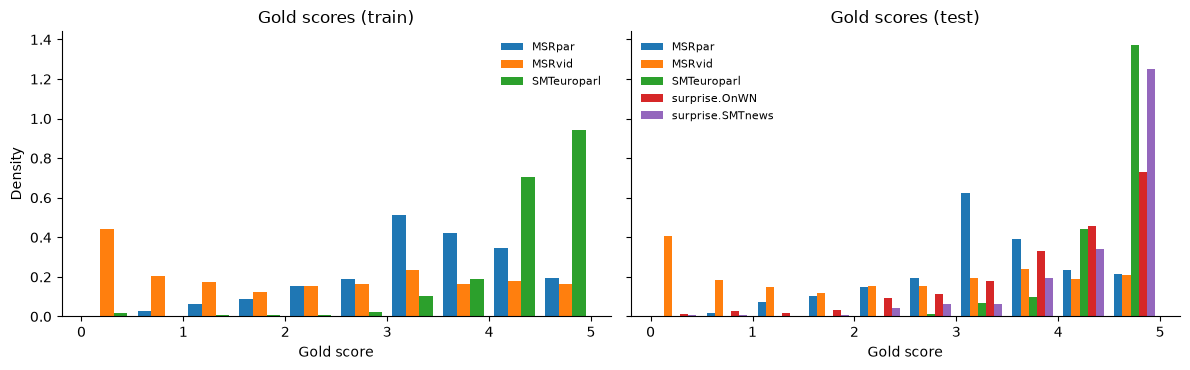

In [4]:
# Distribution of the gold scores of each dataset (train and test).
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
bins = np.linspace(0, 5, 11)
for ax, split, names in [(axes[0], "train", TRAIN_SETS), (axes[1], "test", TEST_SETS)]:
    values = [data[(split, n)][1] for n in names]
    ax.hist(values, bins=bins, label=names, density=True)
    ax.set_title(f"Gold scores ({split})")
    ax.set_xlabel("Gold score")
    ax.legend(fontsize=8, frameon=False)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

The datasets are very different. **MSRvid** pairs are short descriptions of videos with scores spread over the whole scale. **MSRpar** pairs are long news sentences, mostly paraphrases or near-paraphrases. **SMTeuroparl** pairs (and **SMTnews**) are a sentence and its machine translation, with almost all scores near 5. **OnWN** (surprise) pairs a sense definition from OntoNotes with a WordNet gloss. This heterogeneity is the main difficulty of the task: a single model has to work on all of them, and two of the test sets have no training data.

## 2. Evaluation and official results

The three official measures are implemented below and checked with the submissions of the participants: they reproduce the official results of the task (e.g. the baseline `tokencos` with ALL = 0.3110 and the 10th system with ALL = 0.7562, the two thresholds of the project grade).

In [5]:
def evaluate(predictions):
    """Official measures for a dict {test set: predicted scores}."""
    gold = {s: data[("test", s)][1] for s in TEST_SETS}
    all_gold = np.concatenate([gold[s] for s in TEST_SETS])
    result = {"ALL": pearsonr(all_gold, np.concatenate([predictions[s] for s in TEST_SETS]))[0]}
    # ALLnrm: each test set is first normalized with a least-squares fit to its gold standard.
    normalized = []
    for s in TEST_SETS:
        slope, intercept = np.polyfit(predictions[s], gold[s], 1)
        normalized.append(slope * predictions[s] + intercept)
    result["ALLnrm"] = pearsonr(all_gold, np.concatenate(normalized))[0]
    per_set = {s: pearsonr(gold[s], predictions[s])[0] for s in TEST_SETS}
    result["Mean"] = sum(per_set[s] * len(gold[s]) for s in TEST_SETS) / len(all_gold)
    return {**result, **per_set}

def read_submission(folder):
    """Scores of one submitted run (first column; some files have extra columns or blank lines,
    and a few contain "nan", which is counted as 0)."""
    predictions = {}
    for s in TEST_SETS:
        lines = (folder / f"STS.output.{s}.txt").read_text(encoding="utf-8", errors="replace").rstrip().split("\n")
        predictions[s] = np.nan_to_num(np.array([float(line.split()[0]) for line in lines]))
    return predictions

# Evaluate all the runs: the participants and the official baseline (tokencos).
# The random and constant baselines of the organizers are not part of the official ranking.
official = []
for folder in sorted(SUBMISSIONS_DIR.glob("*/*")):
    if not folder.is_dir() or folder.name == "__MACOSX":
        continue
    if folder.parent.name == "00-baseline" and folder.name != "task6-tokencos":
        continue
    official.append({"run": f"{folder.parent.name}/{folder.name.removeprefix('task6-')}",
                     **evaluate(read_submission(folder))})

official = pd.DataFrame(official).sort_values("ALL", ascending=False).reset_index(drop=True)
official.index += 1  # rank
print(f"Official runs (participants + baseline): {len(official)}")
official.head(12).round(4)

Official runs (participants + baseline): 89


,run,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl,surprise.OnWN,surprise.SMTnews
1,baer/UKP-run2_plus_postprocessing_smt_twsi,0.8239,0.8579,0.6773,0.6830,0.8739,0.5280,0.6641,0.4937
2,jan_snajder/takelab-syntax,0.8138,0.8569,0.6601,0.6985,0.8620,0.3612,0.7049,0.4683
3,jan_snajder/takelab-simple,0.8133,0.8635,0.6753,0.7343,0.8803,0.4771,0.6797,0.3989
4,baer/UKP-run1,0.8116,0.8559,0.6708,0.6821,0.8708,0.5118,0.6649,0.4672
5,rada/UNT-IndividualRegression,0.7846,0.8440,0.6162,0.5353,0.8750,0.4203,0.6715,0.4033
6,mheilman/ETS-PERPphrases,0.7834,0.8089,0.6399,0.6397,0.7200,0.4850,0.7124,0.5312
7,mheilman/ETS-PERP,0.7808,0.8064,0.6305,0.6211,0.7210,0.4722,0.7080,0.5149
8,baer/UKP-run3_plus_random,0.7790,0.8166,0.4320,0.6830,0.8739,0.5280,-0.0620,-0.0520
9,rada/UNT-IndividualDecTree,0.7677,0.8389,0.5947,0.5693,0.8688,0.4203,0.6491,0.2256
10,yeh/SRIUBC-SYSTEM2,0.7562,0.8111,0.5858,0.6050,0.7939,0.4294,0.5870,0.3366


In [6]:
# The two thresholds of the project grade.
baseline = official[official["run"] == "00-baseline/tokencos"]
print(f"Baseline (tokencos): ALL = {baseline['ALL'].iloc[0]:.4f}, rank {baseline.index[0]}")
print(f"10th participant:    ALL = {official.loc[10, 'ALL']:.4f} ({official.loc[10, 'run']})")
print(f"Best system:         ALL = {official.loc[1, 'ALL']:.4f} ({official.loc[1, 'run']})")

Baseline (tokencos): ALL = 0.3110, rank 87
10th participant:    ALL = 0.7562 (yeh/SRIUBC-SYSTEM2)
Best system:         ALL = 0.8239 (baer/UKP-run2_plus_postprocessing_smt_twsi)


## 3. Preprocessing

Every sentence is processed once, with two tools:

- **NLTK** (lexical processing): tokenization (`word_tokenize`), POS tagging (averaged perceptron tagger, Penn Treebank tags), lowercasing, lemmatization with the WordNet lemmatizer using the POS tag (as in Lab 3) and marking of stopwords and punctuation. Each token is stored with all these annotations.
- **spaCy** (syntactic processing): dependency parse of the sentence (as in Lab 8), used only for the dependency features of sections 4.2 and 4.3.

In [7]:
STOPWORDS = set(stopwords.words("english"))
LEMMATIZER = nltk.stem.WordNetLemmatizer()
PUNCTUATION = re.compile(r"^\W+$")

def wordnet_pos(tag):
    """Penn Treebank tag -> WordNet POS (None for the other categories)."""
    return {"N": wn.NOUN, "V": wn.VERB, "J": wn.ADJ, "R": wn.ADV}.get(tag[0])

def preprocess(sentence):
    tokens = []
    for word, tag in nltk.pos_tag(nltk.word_tokenize(sentence)):
        pos = wordnet_pos(tag)
        lower = word.lower()
        tokens.append({
            "word": word, "lower": lower, "tag": tag, "pos": pos,
            "lemma": LEMMATIZER.lemmatize(lower, pos) if pos else lower,
            "stop": lower in STOPWORDS, "punct": bool(PUNCTUATION.match(word)),
        })
    return tokens

start = time.time()
processed = {key: [(preprocess(s1), preprocess(s2)) for s1, s2 in pairs] for key, (pairs, gold) in data.items()}
print(f"Preprocessed {sum(len(v) for v in processed.values())} pairs in {time.time() - start:.1f} s\n")

pd.DataFrame(processed[("train", "MSRvid")][0][0])

Preprocessed 5342 pairs in 2.7 s



,word,lower,tag,pos,lemma,stop,punct
0,A,a,DT,NaN,a,True,False
1,man,man,NN,n,man,False,False
2,is,is,VBZ,v,be,True,False
3,riding,riding,VBG,v,rid,False,False
4,a,a,DT,NaN,a,True,False
5,bicycle,bicycle,NN,n,bicycle,False,False
6,.,.,.,NaN,.,False,True


In [9]:
# A known problem of the WordNet lemmatizer: when a form has several possible lemmas it returns the
# shortest one, so "riding" becomes "rid" instead of "ride". How often does it happen in the training data?
candidates = Counter()
for (split, _), pairs in processed.items():
    if split == "train":
        for pair in pairs:
            for t in (x for tokens in pair for x in tokens if x["pos"]):
                options = wn._morphy(t["lower"], t["pos"])
                if len(options) > 1 and options[0] != t["lemma"]:
                    candidates[(t["lower"], t["lemma"], options[0])] += 1
total = sum(len(t1) + len(t2) for (split, _), pairs in processed.items() if split == "train" for t1, t2 in pairs)
print(f"Tokens where the lemma used (the shortest candidate) is not the first WordNet candidate: {sum(candidates.values())} of {total}"
      f" ({sum(candidates.values()) / total:.1%})")
print("Most frequent (form, lemma used, first candidate):", candidates.most_common(6))

Tokens where the lemma used (the shortest candidate) is not the first WordNet candidate: 1092 of 87386 (1.2%)
Most frequent (form, lemma used, first candidate): [(('riding', 'rid', 'ride'), 59), (('affairs', 'affair', 'affairs'), 52), (('conditions', 'condition', 'conditions'), 42), (('found', 'find', 'found'), 40), (('words', 'word', 'words'), 38), (('greater', 'great', 'greater'), 36)]


**A lemmatization problem that we keep.** In the two tables above *riding* is lemmatized as *rid*, with NLTK and with spaCy. The WordNet lemmatizer returns the shortest of the candidate lemmas (*ride*, *rid*). Taking the first candidate instead would fix *riding*, but it is wrong much more often: of the 1092 training tokens where the two rules differ (1.2% of the 87386 tokens), most are plurals that would not be lemmatized at all (*affairs*, *conditions*, *words*). So the NLTK rule is kept. The error is the same in both sentences of a pair, so the overlap measures are not affected; only the WordNet similarity of these words is computed with the wrong lemma.

## 4. Features

Each feature is a similarity (or a difference) between the two sentences of a pair. They are grouped in three families, which correspond to the three dimensions of the statement.

### 4.1 Lexical features

| Group | Features |
|---|---|
| Word overlap | Jaccard of words, lowercased words, lemmas and content lemmas (without stopwords and punctuation); Dice and containment of content lemmas |
| N-grams | Jaccard of lemma bigrams and trigrams; cosine of character 2- to 5-grams |
| Weighting and order | TF-IDF cosine of content lemmas (IDF from the training sentences only); longest common subsequence of lemmas |
| WordNet | Aligned word similarity (each content word matched with its most similar word of the other sentence, IDF-weighted, in both directions; Mihalcea et al., 2006) with the Path, Wu-Palmer and Lin similarities; Jaccard of the most frequent senses (as in Lab 6) |
| Numbers | Jaccard of the numbers, same numbers, one set included in the other; numbers with a close value (same integer after rounding, or less than 2% apart) |
| Length | Ratio of the number of content words; relative difference of length |

In [10]:
def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else 1.0

def dice(a, b):
    a, b = set(a), set(b)
    return 2 * len(a & b) / (len(a) + len(b)) if a or b else 1.0

def containment(a, b):
    a, b = set(a), set(b)
    return len(a & b) / min(len(a), len(b)) if a and b else float(a == b)

def ngrams(sequence, n):
    return [tuple(sequence[i:i + n]) for i in range(len(sequence) - n + 1)]

def cosine(a, b):
    """Cosine of two bags (lists) of items."""
    ca, cb = Counter(a), Counter(b)
    dot = sum(ca[k] * cb[k] for k in ca.keys() & cb.keys())
    norm = math.sqrt(sum(v * v for v in ca.values())) * math.sqrt(sum(v * v for v in cb.values()))
    return dot / norm if norm else 0.0

def lcs_length(a, b):
    table = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(len(a)):
        for j in range(len(b)):
            table[i + 1][j + 1] = table[i][j] + 1 if a[i] == b[j] else max(table[i][j + 1], table[i + 1][j])
    return table[-1][-1]

def content(tokens):
    return [t for t in tokens if not t["stop"] and not t["punct"]]

In [11]:
# IDF of the lemmas, computed on the training sentences only.
train_sentences = [t for (split, _), pairs in processed.items() if split == "train" for pair in pairs for t in pair]
document_frequency = Counter(lemma for t in train_sentences for lemma in {x["lemma"] for x in t})
IDF = {w: math.log(len(train_sentences) / c) for w, c in document_frequency.items()}
MAX_IDF = math.log(len(train_sentences))  # for the words that never appear in the training data

def idf(lemma):
    return IDF.get(lemma, MAX_IDF)

# WordNet similarities between words (cached, because the same words appear many times).
BROWN_IC = wordnet_ic.ic("ic-brown.dat")

@lru_cache(maxsize=None)
def synsets(lemma, pos):
    return tuple(wn.synsets(lemma, pos))

@lru_cache(maxsize=None)
def word_similarity(lemma1, pos1, lemma2, pos2, measure):
    """Maximum similarity between the first 3 senses of two words of the same category."""
    if lemma1 == lemma2:
        return 1.0
    if pos1 != pos2:
        return 0.0
    best = 0.0
    for a in synsets(lemma1, pos1)[:3]:
        for b in synsets(lemma2, pos2)[:3]:
            if measure == "path":
                value = a.path_similarity(b)
            elif measure == "wup":
                value = a.wup_similarity(b)
            elif pos1 in (wn.NOUN, wn.VERB):  # Lin is only defined for nouns and verbs
                value = a.lin_similarity(b, BROWN_IC)
            else:
                value = 0.0
            best = max(best, value or 0.0)
    return best

def aligned_similarity(tokens1, tokens2, measure):
    """Each content word is aligned with its most similar word of the other sentence (IDF-weighted average),
    and the two directions are averaged."""
    c1, c2 = content(tokens1), content(tokens2)
    if not c1 or not c2:
        return 0.0
    def direction(a, b):
        scores = [max(word_similarity(x["lemma"], x["pos"], y["lemma"], y["pos"], measure) for y in b) for x in a]
        weights = [idf(x["lemma"]) for x in a]
        return np.average(scores, weights=weights)
    return (direction(c1, c2) + direction(c2, c1)) / 2

NUMBER = re.compile(r"^[+-]?\d[\d,.]*$")

def numbers(tokens):
    return {t["word"].replace(",", "") for t in tokens if NUMBER.match(t["word"])}

def number_values(tokens):
    values = []
    for text in numbers(tokens):
        try:
            values.append(float(text))
        except ValueError:  # e.g. "1.2.3"
            pass
    return values

def numbers_close(tokens1, tokens2):
    """Proportion of the numbers of each sentence that have a close value in the other one
    (same integer after rounding, or less than 2% apart), averaged over the two directions."""
    a, b = number_values(tokens1), number_values(tokens2)
    if not a or not b:
        return float(not a and not b)
    def close(u, v):
        return round(u) == round(v) or abs(u - v) <= 0.02 * max(abs(u), abs(v))
    def covered(x, y):
        return sum(any(close(u, v) for v in y) for u in x) / len(x)
    return (covered(a, b) + covered(b, a)) / 2

def most_frequent_senses(tokens):
    return {synsets(t["lemma"], t["pos"])[0] for t in tokens if t["pos"] and synsets(t["lemma"], t["pos"])}

In [12]:
def lexical_features(t1, t2):
    f = {}
    lemmas1, lemmas2 = [t["lemma"] for t in t1], [t["lemma"] for t in t2]
    content1, content2 = [t["lemma"] for t in content(t1)], [t["lemma"] for t in content(t2)]

    # Word overlap
    f["jaccard_words"] = jaccard([t["word"] for t in t1], [t["word"] for t in t2])
    f["jaccard_lower"] = jaccard([t["lower"] for t in t1], [t["lower"] for t in t2])
    f["jaccard_lemmas"] = jaccard(lemmas1, lemmas2)
    f["jaccard_content"] = jaccard(content1, content2)
    f["dice_content"] = dice(content1, content2)
    f["containment_content"] = containment(content1, content2)

    # N-grams of lemmas and of characters
    for n in (2, 3):
        f[f"jaccard_lemma_{n}grams"] = jaccard(ngrams(lemmas1, n), ngrams(lemmas2, n))
    text1, text2 = " ".join(t["lower"] for t in t1), " ".join(t["lower"] for t in t2)
    for n in (2, 3, 4, 5):
        f[f"cosine_char_{n}grams"] = cosine(ngrams(text1, n), ngrams(text2, n))

    # TF-IDF cosine and longest common subsequence
    v1, v2 = Counter(content1), Counter(content2)
    dot = sum(v1[w] * v2[w] * idf(w) ** 2 for w in v1.keys() & v2.keys())
    norm = math.sqrt(sum((c * idf(w)) ** 2 for w, c in v1.items())) * math.sqrt(sum((c * idf(w)) ** 2 for w, c in v2.items()))
    f["tfidf_cosine"] = dot / norm if norm else 0.0
    f["lcs_lemmas"] = lcs_length(lemmas1, lemmas2) / max(len(lemmas1), len(lemmas2))

    # WordNet
    for measure in ("path", "wup", "lin"):
        f[f"wordnet_{measure}"] = aligned_similarity(t1, t2, measure)
    f["jaccard_mfs_senses"] = jaccard(most_frequent_senses(t1), most_frequent_senses(t2))

    # Numbers
    n1, n2 = numbers(t1), numbers(t2)
    f["numbers_jaccard"] = jaccard(n1, n2)
    f["numbers_equal"] = float(n1 == n2)
    f["numbers_included"] = float(n1 <= n2 or n2 <= n1)
    f["numbers_close"] = numbers_close(t1, t2)

    # Length
    f["length_ratio"] = min(len(content1), len(content2)) / max(len(content1), len(content2), 1)
    f["length_difference"] = abs(len(t1) - len(t2)) / max(len(t1), len(t2))
    return f

t1, t2 = processed[("train", "MSRvid")][0]
pd.Series(lexical_features(t1, t2)).round(3).to_frame("value").T

,jaccard_words,jaccard_lower,jaccard_lemmas,jaccard_content,dice_content,containment_content,jaccard_lemma_2grams,jaccard_lemma_3grams,cosine_char_2grams,cosine_char_3grams,...,wordnet_path,wordnet_wup,wordnet_lin,jaccard_mfs_senses,numbers_jaccard,numbers_equal,numbers_included,numbers_close,length_ratio,length_difference
value,0.75,0.714,0.714,0.5,0.667,0.667,0.5,0.429,0.869,0.81,...,1.0,1.0,1.0,0.6,1.0,1.0,1.0,1.0,1.0,0.0


## 5. From single measures to learned models

All the choices of this section are made **on the training data only**. The test set is used only once the system is fixed (section 6).

The statement proposes several ways of obtaining a similarity score, from the simplest to the most complex. We follow them in order:

1. **One measure alone**, used directly as the score (as in Labs 2, 3, 6 and 7).
2. **A mixture of measures**: their plain average.
3. **Learned weights**: a linear model (ridge regression) learns the weight of each measure.
4. **A non-linear model** that predicts the score from all the measures (SVR, random forest, gradient boosting).

### 5.1 Measures without learning

In [18]:
# Each feature alone, used directly as a similarity score: Pearson correlation with the gold standard
# on each training set. (A negative value means that the feature is a distance.)
# (Features that are constant in a dataset, e.g. the numbers in MSRvid, have no correlation: NaN.)
with np.errstate(invalid="ignore", divide="ignore"):
    single = pd.DataFrame({s: X[("train", s)].corrwith(pd.Series(y[("train", s)])) for s in TRAIN_SETS})
single["mean |r|"] = single.abs().mean(axis=1)
single["family"] = single.index.str.split(":").str[0]
print("Best features of each family (mean |Pearson| over the three training sets):")
single.sort_values("mean |r|", ascending=False).groupby("family").head(4).round(3)

Best features of each family (mean |Pearson| over the three training sets):


,MSRpar,MSRvid,SMTeuroparl,mean |r|,family
lex:wordnet_path,0.655,0.812,0.540,0.669,lex
lex:tfidf_cosine,0.630,0.794,0.471,0.632,lex
lex:wordnet_lin,0.661,0.737,0.491,0.630,lex
lex:dice_content,0.611,0.768,0.485,0.622,lex
lexsyn:jaccard_lemma_tag,0.529,0.505,0.498,0.511,lexsyn
lexsyn:jaccard_chunk_heads,0.388,0.638,0.367,0.465,lexsyn
lexsyn:jaccard_dep_lexical_triples,0.415,0.583,0.391,0.463,lexsyn
lexsyn:role_object,0.344,0.586,0.438,0.456,lexsyn
syn:cosine_dep_triples,0.372,0.004,0.494,0.290,syn
syn:jaccard_pos_1grams,0.194,-0.154,0.507,0.285,syn


In [19]:
def scores(gold, predictions, sets):
    """ALL, ALLnrm and Mean for dicts {set: array}."""
    g = np.concatenate([gold[s] for s in sets])
    p = np.concatenate([predictions[s] for s in sets])
    normalized = np.concatenate([np.polyval(np.polyfit(predictions[s], gold[s], 1), predictions[s]) for s in sets])
    per_set = {s: pearsonr(gold[s], predictions[s])[0] for s in sets}
    return {"ALL": pearsonr(g, p)[0], "ALLnrm": pearsonr(g, normalized)[0],
            "Mean": sum(per_set[s] * len(gold[s]) for s in sets) / len(g), **per_set}

# Measures without learning, evaluated on the training data: one measure alone, and plain averages of measures.
SIMILARITIES = [c for c in FEATURE_GROUPS["lexical"] if c != "lex:length_difference"]  # all in [0, 1], higher = more similar
BEST_MEASURE = single.loc[FEATURE_GROUPS["lexical"], "mean |r|"].idxmax()
TOP_MEASURES = list(single.loc[SIMILARITIES, "mean |r|"].sort_values(ascending=False).index[:5])
UNSUPERVISED = {
    "Jaccard of words (Lab 2)": lambda X: X["lex:jaccard_words"].to_numpy(),
    "Jaccard of lemmas (Lab 3)": lambda X: X["lex:jaccard_lemmas"].to_numpy(),
    f"best single measure ({BEST_MEASURE.split(':')[1]})": lambda X: X[BEST_MEASURE].to_numpy(),
    f"average of the {len(SIMILARITIES)} lexical similarities": lambda X: X[SIMILARITIES].mean(axis=1).to_numpy(),
    "average of the 5 best measures": lambda X: X[TOP_MEASURES].mean(axis=1).to_numpy(),
}
train_gold = {s: y[("train", s)] for s in TRAIN_SETS}
unsupervised_train = pd.DataFrame({name: scores(train_gold, {s: measure(X[("train", s)]) for s in TRAIN_SETS}, TRAIN_SETS)
                                   for name, measure in UNSUPERVISED.items()}).T
print("5 best measures:", [c.split(":")[1] for c in TOP_MEASURES])
unsupervised_train.round(4)

5 best measures: ['wordnet_path', 'tfidf_cosine', 'wordnet_lin', 'dice_content', 'wordnet_wup']


,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl
Jaccard of words (Lab 2),0.3774,0.6955,0.4584,0.5147,0.3556,0.5058
Jaccard of lemmas (Lab 3),0.4617,0.7462,0.5331,0.5510,0.5410,0.5067
best single measure (wordnet_path),0.7475,0.8521,0.6699,0.6553,0.8117,0.5398
average of the 23 lexical similarities,0.6459,0.8188,0.6497,0.6644,0.7159,0.5670
average of the 5 best measures,0.7224,0.8490,0.6603,0.6564,0.8067,0.5148


**One good measure is better than an average of many.** On the training data, the Jaccard of words of Lab 2 gives ALL = 0.3774 and the Jaccard of lemmas 0.4617. The best single measure, the WordNet aligned similarity with the Path measure, reaches 0.7475: matching each content word with its most similar word and weighting it by IDF is worth much more than counting the shared words. The plain average of the 23 lexical similarities is worse (0.6459), and even the average of the 5 best measures (0.7224) does not improve on the best one: in an average, every measure has the same weight, so the weak ones dilute the good ones. The weights have to be learned.

The syntactic measures alone are weak (the best one, `cosine_dep_triples`, has a mean |Pearson| of 0.290), and in MSRvid they are not correlated with the gold standard at all (0.004), or even negatively (`jaccard_pos_1grams`, -0.154).

### 5.2 Learned models, selected with cross-validation

The measures are now the features of a **regression model** trained on the gold scores, evaluated with a 5-fold cross-validation on the training data.

Choices:

- **Feature set**: lexical, syntactic or combined (all).
- **Model**: ridge regression (linear: a learned weighted sum of the standardized measures), support vector regression with RBF kernel (SVR), random forest (RF) and gradient boosting (GBR).
- **Training strategy**: one *single* model trained on the three training sets together, or one model *per dataset* (each test set is predicted by the model trained on the training set of the same source, as done by the best systems of the task). The surprise sets have no training data: OnWN is predicted with the single model, and SMTnews, which is also machine translation, with the SMTeuroparl model. This choice is made here, before looking at the test set, and it is checked afterwards in section 7.3.

The cross-validation predictions of the 2234 training pairs are evaluated with the same measures as the test set (ALL, ALLnrm and Mean over the three training sets).

## 7. Analysis

### 7.1 From a single measure to a learned model

In [31]:
# The same steps as in section 5, now on the test set: no learning, learned linear weights, non-linear model.
ladder = [{"approach": "official baseline (cosine of tokens)", "learning": "none",
           **{k: baseline[k].iloc[0] for k in ["ALL", "ALLnrm", "Mean"]}}]
for name, measure in UNSUPERVISED.items():
    result = evaluate({s: measure(X[("test", s)]) for s in TEST_SETS})
    ladder.append({"approach": name, "learning": "none", **{k: result[k] for k in ["ALL", "ALLnrm", "Mean"]}})
steps = [("Ridge (learned weights), lexical, single model", ("lexical", "Ridge", "single"), "linear"),
         ("Ridge (learned weights), lexical, per dataset", ("lexical", "Ridge", "per dataset"), "linear"),
         (f"{SYSTEM[1]}, lexical, per dataset", ("lexical", SYSTEM[1], "per dataset"), "non-linear"),
         (f"{SYSTEM[1]}, combined, per dataset (selected)", SYSTEM, "non-linear")]
indexed = test_results.set_index(["features", "model", "strategy"])
for name, key, learning in steps:
    ladder.append({"approach": name, "learning": learning, **indexed.loc[key, ["ALL", "ALLnrm", "Mean"]]})
ladder = pd.DataFrame(ladder).set_index("approach")
ladder["rank (ALL)"] = ladder["ALL"].map(official_rank)
ladder.round(4)

,learning,ALL,ALLnrm,Mean,rank (ALL)
approach,,,,,
official baseline (cosine of tokens),none,0.3110,0.6732,0.4356,87
Jaccard of words (Lab 2),none,0.3579,0.6947,0.4776,83
Jaccard of lemmas (Lab 3),none,0.4313,0.7435,0.5410,76
best single measure (wordnet_path),none,0.6737,0.8347,0.6323,23
average of the 23 lexical similarities,none,0.5873,0.8080,0.6281,50
average of the 5 best measures,none,0.6471,0.8310,0.6298,35
"Ridge (learned weights), lexical, single model",linear,0.7239,0.8395,0.6462,18
"Ridge (learned weights), lexical, per dataset",linear,0.8045,0.8522,0.6688,5
"RF, lexical, per dataset",non-linear,0.8199,0.8621,0.6970,2


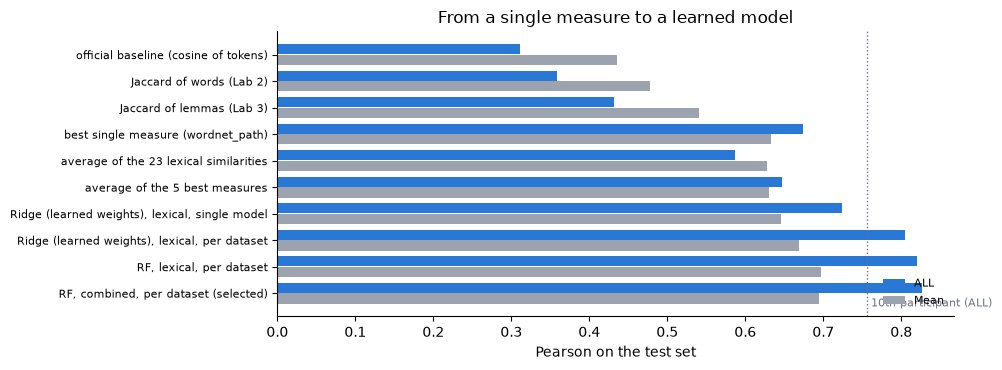

In [32]:
fig, ax = plt.subplots(figsize=(10, 3.8))
labels = list(ladder.index)
positions = np.arange(len(ladder))
ax.barh(positions, ladder["ALL"], height=0.38, color="#2a78d6", label="ALL")
ax.barh(positions + 0.4, ladder["Mean"], height=0.38, color="#9ca3af", label="Mean")
ax.axvline(official.loc[10, "ALL"], color="#6b7280", linestyle=":", linewidth=1)
ax.text(official.loc[10, "ALL"] + 0.005, len(ladder) - 0.3, "10th participant (ALL)", fontsize=8, color="#6b7280")
ax.set_yticks(positions + 0.2, labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Pearson on the test set")
ax.set_title("From a single measure to a learned model")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

Each step of the statement's strategies can be read in this table:

| Step | ALL (test) | What it adds |
|---|---|---|
| Jaccard of words → Jaccard of lemmas | 0.3579 → 0.4313 | Normalizing the words |
| → best single measure (WordNet alignment, IDF) | 0.6737 | Matching similar words, and weighting the informative ones |
| → plain average of the 23 measures | 0.5873 | Nothing: it is *worse* than the best measure alone |
| → learned weights (ridge), single model | 0.7239 | The weights of the measures |
| → learned weights, one model per dataset | 0.8045 | The score level of each dataset |
| → non-linear model (RF), lexical | 0.8199 | Interactions between the measures |
| → non-linear model, combined features | 0.8263 | Syntactic information |

- **A single well-designed measure, without any learning, would already be 23rd of 89** (0.6737), far above the baseline (0.3110) and the Jaccard of words of Lab 2 (0.3579).
- **Averaging measures does not help; learning their weights does.** The plain average of the 23 lexical similarities gives 0.5873, and that of the 5 best ones 0.6471, both below the best single measure. The ridge regression, which uses the same measures with learned weights, reaches 0.7239.
- **The largest step after that is not a better model but one model per dataset** (0.7239 → 0.8045, rank 18 → 5 with the same linear model). Section 7.3 shows that this is mostly a matter of score level.
- **The non-linear model adds 0.0154 and the syntactic information 0.0064.** A linear combination of lexical measures, with one model per dataset, already gives 97% of the final ALL.

Note that ALLnrm and Mean change much less than ALL along the table (the best single measure already has ALLnrm = 0.8347 and Mean = 0.6323): ALL is very sensitive to the score level of each dataset, which the other two measures ignore.

### 7.2 Results by dataset, compared with the best systems

In [33]:
# Pearson on each test set: our three systems, the two best participants and the baseline.
top_runs = ["baer/UKP-run2_plus_postprocessing_smt_twsi", "jan_snajder/takelab-simple", "00-baseline/tokencos"]
by_dataset = pd.concat([
    summary.reset_index().assign(run=lambda d: "OURS " + d["features"]).set_index("run")[TEST_SETS + ["ALL"]],
    official.set_index("run").loc[top_runs, TEST_SETS + ["ALL"]],
])
by_dataset.round(4)

,MSRpar,MSRvid,SMTeuroparl,surprise.OnWN,surprise.SMTnews,ALL
run,,,,,,
OURS lexical,0.6879,0.8684,0.5391,0.6937,0.5794,0.8199
OURS syntactic,0.3758,0.3597,0.3030,0.2226,0.3145,0.5384
OURS combined,0.6929,0.8784,0.5101,0.6967,0.5610,0.8263
baer/UKP-run2_plus_postprocessing_smt_twsi,0.6830,0.8739,0.5280,0.6641,0.4937,0.8239
jan_snajder/takelab-simple,0.7343,0.8803,0.4771,0.6797,0.3989,0.8133
00-baseline/tokencos,0.4334,0.2996,0.4542,0.5864,0.3908,0.3110


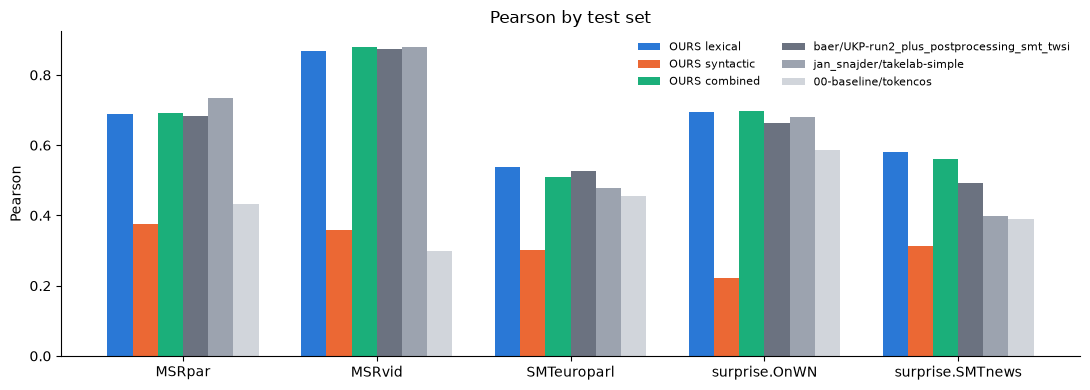

In [34]:
fig, ax = plt.subplots(figsize=(11, 4))
width = 0.13
runs = list(by_dataset.index)
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#6b7280", "#9ca3af", "#d1d5db"]
for i, run in enumerate(runs):
    ax.bar(np.arange(len(TEST_SETS)) + (i - len(runs) / 2 + 0.5) * width, by_dataset.loc[run, TEST_SETS],
           width, label=run, color=palette[i])
ax.set_xticks(range(len(TEST_SETS)), TEST_SETS)
ax.set_ylabel("Pearson")
ax.set_title("Pearson by test set")
ax.axhline(0, color="black", linewidth=0.5)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

- **Compared with the best official system (UKP), our combined system is higher on four of the five test sets**: MSRpar (0.6929 vs 0.6830), MSRvid (0.8784 vs 0.8739), OnWN (0.6967 vs 0.6641) and especially SMTnews (0.5610 vs 0.4937). It is lower on SMTeuroparl (0.5101 vs 0.5280). On MSRpar, TakeLab is clearly better than both (0.7343).
- **MSRvid is the easiest set** (0.8784): short sentences with the same simple structure, where the overlap of the content words and their WordNet similarity is very informative.
- **The machine translation sets (SMTeuroparl and SMTnews) are the hardest** for all the systems: their gold scores are concentrated between 4 and 5 (section 1), so small errors change the ranking of the pairs a lot, and the second sentence is often ungrammatical.
- **The combination is not better everywhere.** Compared with our lexical system it gains on MSRvid (0.8684 → 0.8784) and MSRpar (0.6879 → 0.6929), and loses on SMTeuroparl (0.5391 → 0.5101) and SMTnews (0.5794 → 0.5610). The translation sets are predicted by the SMTeuroparl model, where the syntactic features looked useful in cross-validation (section 5.2) but do not transfer to the test set: the syntactic system alone has 0.7176 on SMTeuroparl in cross-validation and 0.3030 on the test set.
- **The surprise sets work reasonably well without training data of their own** (OnWN 0.6967, SMTnews 0.5610), which shows that the features generalize across sources.

### 7.5 Error analysis

In [41]:
# Largest errors of the selected system on each test set.
system_predictions = test_predictions[SYSTEM]
for s in TEST_SETS:
    pairs, gold = data[("test", s)]
    errors = system_predictions[s] - gold
    print(f"=== {s}: mean absolute error {np.abs(errors).mean():.3f}")
    for i in [int(np.argmax(errors)), int(np.argmin(errors))]:
        print(f"  gold {gold[i]:.2f}  predicted {system_predictions[s][i]:.2f}")
        print(f"    S1: {pairs[i][0]}")
        print(f"    S2: {pairs[i][1]}")
    print()

=== MSRpar: mean absolute error 0.516
  gold 1.00  predicted 3.26
    S1: The woman was hospitalized June 15, Kansas health officials said.
    S2: Missouri health officials said he had not been hospitalized and is recovering.
  gold 4.60  predicted 2.69
    S1: But butterflies exposed to an earlier light cycle, from 1am to 1pm, orientated themselves towards the south-east.
    S2: But butterflies housed under an earlier light cycle, 1 a.m. to 1 p.m., flew toward the southeast.

=== MSRvid: mean absolute error 0.565
  gold 1.50  predicted 3.79
    S1: Two men are talking.
    S2: Two men are playing guitar.
  gold 4.00  predicted 0.29
    S1: A woman puts cosmetics on her eyelid.
    S2: The woman is pencilling on eye shadow.

=== SMTeuroparl: mean absolute error 0.478
  gold 3.00  predicted 4.51
    S1: The standards are scarcely comparable, let alone transferable.
    S2: The rules are comparable only good, let alone.
  gold 4.50  predicted 1.58
    S1: The vote will take place today

In [42]:
# Mean prediction for each range of gold scores: the system compresses the scale towards the
# training average (over-predicts the dissimilar pairs and under-predicts the equivalent ones).
all_gold = np.concatenate([y[("test", s)] for s in TEST_SETS])
all_pred = np.concatenate([system_predictions[s] for s in TEST_SETS])
ranges = pd.cut(all_gold, [0, 1, 2, 3, 4, 5], include_lowest=True)
pd.DataFrame({"gold": all_gold, "predicted": all_pred}).groupby(ranges, observed=True).agg(
    pairs=("gold", "size"), mean_gold=("gold", "mean"), mean_predicted=("predicted", "mean")).round(3)

,pairs,mean_gold,mean_predicted
"(-0.001, 1.0]",288,0.402,0.786
"(1.0, 2.0]",203,1.648,2.128
"(2.0, 3.0]",430,2.680,2.831
"(3.0, 4.0]",915,3.636,3.361
"(4.0, 5.0]",1272,4.692,4.038


In [43]:
# Types of error: the pairs with the largest errors, by the overlap of their content words.
rows = []
for s in TEST_SETS:
    for i, error in enumerate(system_predictions[s] - y[("test", s)]):
        rows.append({"set": s, "error": error, "content overlap": X[("test", s)].loc[i, "lex:jaccard_content"]})
errors = pd.DataFrame(rows)
large = errors[errors["error"].abs() >= 1.5]
print(f"Pairs with an absolute error of 1.5 or more: {len(large)} of {len(errors)} ({len(large) / len(errors):.1%})")
summary_errors = pd.DataFrame({
    "pairs": errors.groupby("set", sort=False).size(),
    "error >= 1.5 (over-predicted)": large[large["error"] > 0].groupby("set").size(),
    "error <= -1.5 (under-predicted)": large[large["error"] < 0].groupby("set").size(),
    "content overlap, over-predicted": large[large["error"] > 0].groupby("set")["content overlap"].mean(),
    "content overlap, under-predicted": large[large["error"] < 0].groupby("set")["content overlap"].mean(),
    "content overlap, all pairs": errors.groupby("set")["content overlap"].mean(),
}).fillna(0)
summary_errors.round(3)

Pairs with an absolute error of 1.5 or more: 205 of 3108 (6.6%)


,pairs,error >= 1.5 (over-predicted),error <= -1.5 (under-predicted),"content overlap, over-predicted","content overlap, under-predicted","content overlap, all pairs"
set,,,,,,
MSRpar,750,21,9,0.431,0.264,0.451
MSRvid,750,17,28,0.343,0.225,0.345
SMTeuroparl,459,1,12,0.375,0.318,0.500
surprise.OnWN,750,3,94,0.125,0.126,0.456
surprise.SMTnews,399,8,12,0.302,0.317,0.466


In [44]:
# Two pairs with the same numbers written in a different format.
examples = [("MSRpar", "13.73 points"), ("SMTeuroparl", "The vote will be to 17h30")]
for s, text in examples:
    pairs, gold = data[("test", s)]
    i = next(i for i, (s1, s2) in enumerate(pairs) if text in s2)
    print(f"{s}: gold {gold[i]:.2f}, predicted {system_predictions[s][i]:.2f}")
    print(f"  S1: {pairs[i][0]}\n  S2: {pairs[i][1]}")
    t1, t2 = processed[("test", s)][i]
    print(f"  numbers: {sorted(numbers(t1))} / {sorted(numbers(t2))}")
    print(f"  numbers_jaccard = {X[('test', s)].loc[i, 'lex:numbers_jaccard']:.2f}, numbers_close = {X[('test', s)].loc[i, 'lex:numbers_close']:.2f}\n")

MSRpar: gold 3.75, predicted 1.99
  S1: The Nasdaq composite index rose 13.70, or 0.8 per cent, to 1700.34.
  S2: The technology-laced Nasdaq Composite Index .IXIC gained 13.73 points, or 0.81 percent, to finish at 1,700.34.
  numbers: ['0.8', '13.70', '1700.34'] / ['0.81', '13.73', '1700.34']
  numbers_jaccard = 0.20, numbers_close = 1.00

SMTeuroparl: gold 4.50, predicted 1.58
  S1: The vote will take place today at 5.30 p.m.
  S2: The vote will be to 17h30.
  numbers: ['5.30'] / []
  numbers_jaccard = 0.00, numbers_close = 0.00



**The large errors are a minority, and their type depends on the dataset.** 205 of the 3108 pairs (6.6%) have an absolute error of 1.5 or more. Almost half of them are **under-predictions in OnWN** (94 pairs): two definitions of the same concept written with different words. Their mean content overlap is 0.126, against 0.456 for all the OnWN pairs, and the mean absolute error of OnWN (0.845) is the highest of the five sets. In MSRpar, the large errors are mostly over-predictions (21 against 9): long news sentences that share many words but report different facts.

The examples show the limits of a feature-based system without a representation of the meaning of the whole sentence:

- **Paraphrases without shared words.** OnWN *"restrict or confine"* / *"place limits on (extent or access)"* (gold 4.75, predicted 0.30), MSRvid *"A woman puts cosmetics on her eyelid"* / *"The woman is pencilling on eye shadow"* (gold 4.00, predicted 0.29) and SMTnews *"Other ways are needed"* / *"It is necessary to find other means"* (gold 4.50, predicted 1.33). WordNet only relates single words of the same category, so it cannot match *restrict* with *place limits on*.
- **High overlap, different meaning.** MSRvid *"Two men are talking"* / *"Two men are playing guitar"* (gold 1.50, predicted 3.79), MSRpar *"The woman was hospitalized June 15, Kansas health officials said"* / *"Missouri health officials said he had not been hospitalized and is recovering"* (gold 1.00, predicted 3.26) and OnWN *"(Cause to) smell bad"* / *"be extremely bad in quality..."* (gold 0.00, predicted 2.66): they share words, but the event, the participants or the polarity (*not*) are different.
- **Ungrammatical translations.** SMTeuroparl *"The rules are comparable only good, let alone."* (gold 3.00, predicted 4.51): it shares most content words with the source, but it lost part of the meaning.
- **Different formats of the same information.** An earlier version of the system compared the numbers only as strings, and two of its largest errors were of this kind. The feature `numbers_close` was added for them, with a partial result:
  - *13.70* / *13.73* and *0.8 per cent* / *0.81 percent* (MSRpar, gold 3.75): the numbers now match (`numbers_close` = 1.00, while `numbers_jaccard` = 0.20), but the prediction is still low (1.99), because the rest of the sentence is also worded differently.
  - *"5.30 p.m."* / *"17h30"* (SMTeuroparl, gold 4.50, predicted 1.58): not solved. *17h30* is not recognized as a number, and matching the two would need a normalization of time expressions. The same happens with *1am to 1pm* / *1 a.m. to 1 p.m.* in MSRpar (gold 4.60, predicted 2.69).

Finally, the predictions are **compressed towards the middle of the scale**: the pairs with a gold score up to 1 get a mean prediction of 0.786 (gold 0.402), and those above 4 a mean of 4.038 (gold 4.692). This is the usual behaviour of a regression model trained with a squared error (and of random forests, which average the training targets), and it does not affect the Pearson correlation much, as it is a monotonic effect.

## 8. Comparison with the systems of the participants

In [45]:
# Official results of the systems of the table below (rank by ALL and by Mean among the 89 runs).
runs = ["baer/UKP-run2_plus_postprocessing_smt_twsi", "jan_snajder/takelab-syntax", "jan_snajder/takelab-simple",
        "mheilman/ETS-PERPphrases", "yeh/SRIUBC-SYSTEM2", "sgjimenezv/SOFT-CARDINALITY"]
papers = official.assign(**{"rank (ALL)": official.index, "rank (Mean)": official["Mean"].rank(ascending=False).astype(int)})
papers[papers["run"].isin(runs)][["run", "ALL", "rank (ALL)", "ALLnrm", "Mean", "rank (Mean)"]].round(4)

,run,ALL,rank (ALL),ALLnrm,Mean,rank (Mean)
1,baer/UKP-run2_plus_postprocessing_smt_twsi,0.8239,1,0.8579,0.6773,1
2,jan_snajder/takelab-syntax,0.8138,2,0.8569,0.6601,5
3,jan_snajder/takelab-simple,0.8133,3,0.8635,0.6753,2
6,mheilman/ETS-PERPphrases,0.7834,6,0.8089,0.6399,7
10,yeh/SRIUBC-SYSTEM2,0.7562,10,0.8111,0.5858,33
15,sgjimenezv/SOFT-CARDINALITY,0.7331,15,0.8526,0.6708,3


The numbers of section 6 compare the results; this table compares the methods, from the papers of the participants.

| System | ALL | Measures | Combination | Beyond the task data |
|---|---|---|---|---|
| UKP (1st) | 0.8239 | String measures, character and word n-grams, WordNet word similarity (Resnik) aligned as in Mihalcea et al., Explicit Semantic Analysis; text expansion with lexical substitution and machine translation | Log-linear regression of about 20 measures selected from 300+; one model per dataset, joint model for the surprise sets | Wikipedia, Wiktionary, a distributional thesaurus, an SMT system trained on Europarl |
| TakeLab (2nd, 3rd) | 0.8138, 0.8133 | N-gram overlap, WordNet-augmented overlap, vector space similarity, syntactic roles, dependency overlap, numbers, normalized differences | SVR | LSA word vectors from the New York Times corpus and Wikipedia |
| ETS (6th, 7th) | 0.7834 | Edit operations between the two sentences (from the machine translation metric TERp) | Discriminative model over the edits | Paraphrase and synonym resources of TERp |
| SRIUBC (10th) | 0.7562 | Semantic similarity resources, lexical matching, POS, BLEU-like precision, skip-bigrams | SVR | Semantic similarity resources |
| Soft Cardinality (15th) | 0.7331 | Soft cardinality of character q-grams | Parameterized resemblance coefficient | Nothing (a stopword list and a stemmer) |
| **Ours** | **0.8263** | 24 lexical (overlap, n-grams, TF-IDF, WordNet alignment, numbers, length), 21 syntactic (POS, chunks, dependencies), 14 lexico-syntactic | Random forest, one model per dataset; SMTeuroparl model for SMTnews | Nothing: WordNet and its information content (NLTK), parser of spaCy |

- **Our system is closest to UKP and TakeLab in its design**: many simple measures, a WordNet word alignment weighted by IDF, numbers and length, and a regression model trained for each dataset. The measures that our ablation finds useful are the ones they report: the WordNet alignment (UKP, TakeLab), the numbers (TakeLab added them for the same reason, pairs with different figures) and the lexicalized dependencies and syntactic roles (TakeLab).
- **The main difference is what we do not use.** The two best teams relied on distributional information from large corpora (Explicit Semantic Analysis, LSA vectors), which the statement of the project does not allow. Our result shows that, on this test set, WordNet and good surface measures are enough to reach the same level. It does not show that the distributional information is useless: the errors of section 7.5 (paraphrases without shared words) are exactly the cases that it addresses.
- **Purely syntactic or structural measures were not useful for the participants either.** UKP reports that their structure and style measures (POS n-grams, stopword n-grams, word order) were not selected by their model, which agrees with our ablation.
- **Where we are different from UKP**: a non-linear model instead of a log-linear one (section 7.1: +0.0154 over the linear model with the same lexical features), and the SMTeuroparl model for SMTnews instead of a joint model (section 7.3).
- **Where the others are better**: TakeLab on MSRpar (0.7343 against 0.6929), the long news sentences. Soft Cardinality shows how far surface information alone can go: 15th on ALL (0.7331), but 3rd on Mean (0.6708).

## 9. Conclusions

- **Result.** With the data of the task, WordNet and no embeddings, the selected system (59 features, random forest, one model per dataset) reaches **ALL = 0.8263, ALLnrm = 0.8654 and Mean = 0.6946** on the test set. This is at the level of the best official system (UKP, 0.8239): the difference is not significant (95% interval [-0.0077, 0.0122]). It is well above the 10th participant (0.7562) and the baseline (0.3110).
- **The lexical dimension is the core of the system** (0.8199 alone). A single measure without learning, the WordNet alignment weighted by IDF, already gives 0.6737, against 0.3579 for the Jaccard of words.
- **The syntactic dimension alone is not enough** (0.5384): the same structure can carry different meanings.
- **The combination adds a small, consistent gain on ALL** (+0.0064, interval [0.0020, 0.0109]), which comes from the lexico-syntactic features: syntax is useful to decide *which* words to compare, not as an independent signal. On the translation sets the combination is worse than the lexical system.
- **How the measures are combined matters as much as the measures.** A plain average is worse than the best measure alone; learned weights add 0.05; and one model per dataset adds 0.08 to ALL with the same linear model, mostly by predicting the right score level for each dataset, which ALLnrm and Mean do not reward.
- **Sources without training data** are the weak point: in the leave-one-dataset-out experiment the correlation drops by 0.11 to 0.28, and OnWN has the largest errors. Choosing a model trained on a similar source helps (SMTnews: 0.5610 with the SMTeuroparl model, 0.5134 with the single model).
- **Main limitations**: paraphrases with no shared words (multiword expressions, definitions), sentences that share words but differ in the event or the polarity, and different formats of times and dates. The differences between the best configurations are small compared with the uncertainty of the test set, so the ranking among them should not be over-interpreted.
- **Possible improvements without embeddings**: normalizing times and dates; aligning multiword expressions with WordNet; detecting negation; and a model of the source of a pair, to choose the model for an unseen dataset automatically.